In [1]:
from util.getVideo import*
from util.makeVideo import*
from util.plotGraph import*
from util.YTdownload import download_videos
from extractHighlight import*
import time


def event_cnt(interval, event_lst):
    cnt = 0

    for elem in interval:
        start, end = elem
        end += 1
        for i in event_lst:
            if start <= i <= end:
                cnt +=1
    return cnt

def interval_time(interval):
    total_duration = 0
    for start, end in interval:
        total_duration += end - start + 1
    return total_duration


def plot_all(dic, min_time):
    plt.figure(figsize=(5, 3))

    for key, value in dic.items():
        times, counts = zip(*value)
        plt.plot(times, counts, label=key, marker='o', linestyle='-', linewidth=1, markersize=3)

    plt.xlabel('Time(minutes)')
    plt.ylabel('Count')
    plt.title(f'DP, Threshold, Knapsack - min time {min_time}')
    plt.legend()
    plt.grid(True)

    plt.savefig('comparison_graph_step.png')




fetch data!!!
fetch data finsihed!!!
Total lengths:101
==== id Cbij3MKhdOY original time 101 total time: 15, min time: 3 start!!! ====
===Start threshold===
===Start knapsack===
===Start DP===
DP end with 0.19676470756530762


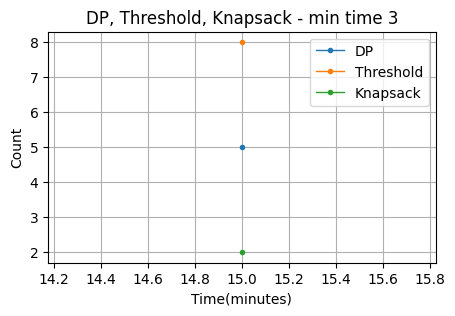

In [3]:
log_file = "process_log.txt"
if __name__ == "__main__":
    ROOT = "/source/ms"
    source_path = f"{ROOT}/highlight/source/pre_usertest"
    json_root = f"{ROOT}/highlight/json"
    video_ids = video_ids = ["Cbij3MKhdOY"]
    event_lst = [13, 15, 21, 43, 45, 52, 62, 68, 73, 97]

    min_time = 3
    knapsack_length = 3
    cnt_dic = {"DP":[], "Threshold":[], "Knapsack":[]} #시간,  cnt 형태로 담겨 있음
    with open(log_file, "a") as log:
        for video_id in video_ids:
            json_path = f'{json_root}/{video_id}.json'
            print("fetch data!!!")
            data = fetch_video_data(video_id, json_path, save = os.path.exists(json_path))
            print("fetch data finsihed!!!")
            start_seconds, intensity_scores = process_video_data(data)
            smoothed_intensity_scores = interpolate(start_seconds, intensity_scores)

            print(f"Total lengths:{len(smoothed_intensity_scores)}")
            video_path = os.path.join(source_path, f'{video_id}.mp4')

            total_times = [15]
            # total_times = np.arange(3, 40, 1)
            # total_times = np.arange(1, len(intensity_scores), 1)

            for total_time in total_times:
                message = f"==== id {video_id} original time {len(smoothed_intensity_scores)} total time: {total_time}, min time: {min_time} start!!! ===="
                print(message)
                log.write(message + "\n")
                run_higlight_methods = Run(
                    smoothed_intensity_scores=smoothed_intensity_scores,
                    total_time=total_time,
                    min_time=min_time,
                )
                dp_intervals, threshold_c, threshold_intervals, knapsack_intervals = run_higlight_methods.run_all(knapsack_length)
                
                cnt_dic["DP"].append((interval_time(dp_intervals), event_cnt(dp_intervals, event_lst)))
                cnt_dic["Threshold"].append((interval_time(threshold_intervals), event_cnt(threshold_intervals, event_lst)))
                cnt_dic["Knapsack"].append((interval_time(knapsack_intervals), event_cnt(knapsack_intervals, event_lst)))
            
            # print(cnt_dic)
            plot_all(cnt_dic, min_time)

In [8]:
dp_intervals

[(41, 44), (60, 63), (67, 73)]

In [6]:
threshold_intervals

[(0, 0), (12, 13), (42, 44), (52, 53), (61, 62), (67, 68), (72, 73), (97, 97)]

In [7]:
knapsack_intervals

[(9, 11), (39, 41), (60, 62), (66, 71)]

# 15 분 지점

In [18]:
def analyze_intervals(lst):
    c_values = [b - a + 1 for a, b in lst]
    print(c_values)
    
    # 평균 계산
    avg = sum(c_values) / len(c_values)
    
    # 분산 계산
    mean = avg
    variance = sum((x - mean) ** 2 for x in c_values) / len(c_values)
    
    # 최소값과 최대값
    min_val = min(c_values)
    max_val = max(c_values)
    
    return avg, variance, min_val, max_val

In [19]:
average, variance, minimum, maximum = analyze_intervals(dp_intervals)

print(f"평균: {average}")
print(f"분산: {variance}")
print(f"최소값: {minimum}")
print(f"최대값: {maximum}")

[4, 4, 7]
평균: 5.0
분산: 2.0
최소값: 4
최대값: 7


In [20]:
average, variance, minimum, maximum = analyze_intervals(threshold_intervals)

print(f"평균: {average}")
print(f"분산: {variance}")
print(f"최소값: {minimum}")
print(f"최대값: {maximum}")

[1, 2, 3, 2, 2, 2, 2, 1]
평균: 1.875
분산: 0.359375
최소값: 1
최대값: 3


In [21]:
average, variance, minimum, maximum = analyze_intervals(knapsack_intervals)

print(f"평균: {average}")
print(f"분산: {variance}")
print(f"최소값: {minimum}")
print(f"최대값: {maximum}")

[3, 3, 3, 6]
평균: 3.75
분산: 1.6875
최소값: 3
최대값: 6
